In [2]:
import numpy as np 
import matplotlib.pyplot as plt
def true_function(x):
    return np.sin(1.5*x)+0.5*x

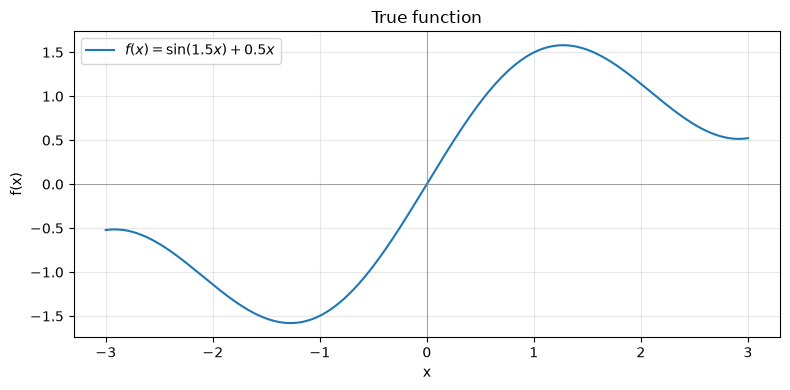

In [3]:
x=np.linspace(-3,3,400)
y=true_function(x)

plt.figure(figsize=(8, 4))
plt.plot(x, y, label=r"$f(x) = \sin(1.5x) + 0.5x$", color="tab:blue")
plt.axhline(0, color="gray", linewidth=0.5)   # x-axis reference
plt.axvline(0, color="gray", linewidth=0.5)   # y-axis reference
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("True function")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [4]:
import random
def generate_data(n_samples=30,noise_std=0.5,x_range=(-3,3),seed=42):
    rng=np.random.RandomState(seed)
    x=rng.uniform(x_range[0],x_range[1],n_samples)
    y=true_function(x) + rng.normal(0,noise_std,n_samples)
    return x,y

In [5]:
x, y = generate_data(n_samples=30, seed=0)
assert x.shape == (30,) and y.shape == (30,)
assert x.min() >= -3 and x.max() <= 3

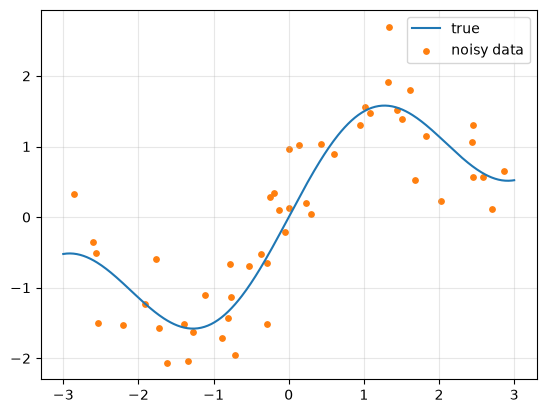

In [6]:
x_clean = np.linspace(-3, 3, 400)
plt.plot(x_clean, true_function(x_clean), label="true", color="tab:blue")

x, y = generate_data(n_samples=50, noise_std=0.5, seed=7)
plt.scatter(x, y, color="tab:orange", s=15, label="noisy data")
plt.legend(); plt.grid(alpha=0.3); plt.show()

In [7]:
import numpy as np


def fit_polynomial(x_train, y_train, degree, lam=0.0):
    """
    Fit a degree-`degree` polynomial to (x_train, y_train).
    If lam > 0, use ridge regression (intercept not penalized).
    Returns weight vector w of length degree + 1.
    """
    # --- Build the design matrix X, shape (n, degree+1) ---
    # Column j holds x**j, so row i is [1, x_i, x_i^2, ..., x_i^degree]
    X = np.column_stack([x_train ** d for d in range(degree + 1)])
    #       ^ shape (n,) for each d  →  column_stack makes (n, degree+1)
    #       d=0 gives x**0 = 1 (the intercept column)

    if lam == 0.0:
        # --- Ordinary least squares ---
        # lstsq returns several items; [0] is the solution vector w.
        w = np.linalg.lstsq(X, y_train, rcond=None)[0]

    else:
        # --- Ridge regression ---
        # Normal equation: (X^T X + λI') w = X^T y
        # where I' is the identity with [0,0] set to 0 (intercept unpenalized).
        XtX = X.T @ X                             # shape (degree+1, degree+1)
        penalty = lam * np.eye(degree + 1)        # λ·I
        penalty[0, 0] = 0.0                       # do NOT penalize intercept
        Xty = X.T @ y_train                       # shape (degree+1,)
        w = np.linalg.solve(XtX + penalty, Xty)   # solve the linear system

    return   w                                       # shape (degree+1,)

In [8]:
if __name__ == "__main__":
    # Test 1: exact recovery on a known line
    x = np.linspace(-2, 2, 20)
    y = 2.0 + 3.0 * x
    w = fit_polynomial(x, y, degree=1)
    print("Test 1 — exact line, degree 1:")
    print("  w =", w, "   expected ≈ [2.0, 3.0]")

    # Test 2: ridge shrinks slope but NOT intercept
    w = fit_polynomial(x, y, degree=1, lam=100.0)
    print("\nTest 2 — same data, ridge lam=100:")
    print("  w =", w)
    print("  intercept w[0] should still be ≈ 2")
    print("  slope    w[1] should be shrunk toward 0")

    # Test 3: shape check across degrees
    x, y = np.random.randn(30), np.random.randn(30)  # any data, just check shape
    for d in [1, 3, 5, 9]:
        w = fit_polynomial(x, y, degree=d)
        print(f"\nTest 3 — degree {d}: w.shape = {w.shape}  (expected ({d+1},))")

Test 1 — exact line, degree 1:
  w = [2. 3.]    expected ≈ [2.0, 3.0]

Test 2 — same data, ridge lam=100:
  w = [2.         0.68292683]
  intercept w[0] should still be ≈ 2
  slope    w[1] should be shrunk toward 0

Test 3 — degree 1: w.shape = (2,)  (expected (2,))

Test 3 — degree 3: w.shape = (4,)  (expected (4,))

Test 3 — degree 5: w.shape = (6,)  (expected (6,))

Test 3 — degree 9: w.shape = (10,)  (expected (10,))


In [9]:
x, y = generate_data(n_samples=200, noise_std=0.5, seed=0)
w = fit_polynomial(x, y, degree=1)
print("Degree 1 fit on noisy data:", w)

Degree 1 fit on noisy data: [0.0179853  0.46708322]


In [15]:
x=np.array([1,2,3])
degree=2
np.column_stack([x**d for d in range(degree+1)])

array([[1, 1, 1],
       [1, 2, 4],
       [1, 3, 9]])

In [10]:
def predict_polynomial(x,w):
    degree=len(w)-1 
    X=np.column_stack([x**d for d in range(degree+1)])
    return X@w

In [11]:
x = np.linspace(-2, 2, 20)
y = 2.0 + 3.0 * x
w = fit_polynomial(x, y, degree=1)
pred = predict_polynomial(x, w)
print("max |pred - y| =", np.max(np.abs(pred - y)))
# expected: ~1e-14 (machine precision — a line fits a line exactly)

max |pred - y| = 2.6645352591003757e-15


In [12]:
x_new = np.array([-1.0, 0.0, 1.0, 2.0])   # 4 points, different from training
pred = predict_polynomial(x_new, w)        # use same w from above
print(pred)                                # expected: [-1, 2, 5, 8]  (2 + 3x)

[-1.  2.  5.  8.]


In [16]:
x_train, y_train = generate_data(n_samples=100, noise_std=0.5, seed=0)
w = fit_polynomial(x_train, y_train, degree=3)
pred = predict_polynomial(x_train, w)
print("train MSE =", np.mean((pred - y_train)**2))
# should be fairly small (< noise²=0.25 is possible, but a few times smaller than
# a degree-1 fit's MSE is a good sign)

train MSE = 0.3082098570945985
